In [3]:
%pip install -U microlens_submit
%pip install -U RTModel==3.3
%pip install -U jacscanomaly
%pip install -U microjax
%pip uninstall -U pyAethra
%pip install -U pyAethra
%pip install datasets pandas pyarrow duckdb huggingface_hub

%pip install seaborn

  Using cached microlens_submit-0.17.9-py3-none-any.whl.metadata (10 kB)
  Using cached typer-0.27.3-py3-none-any.whl.metadata (16 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
Using cached microlens_submit-0.17.9-py3-none-any.whl (1.1 MB)
Using cached typer-0.27.3-py3-none-any.whl (123 kB)
Using cached annotated_doc-0.0.5-py3-none-any.whl (5.3 kB)
Using cached shellingham-1.5.4-py2.py3-none-any.whl (9.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [microlens_submit][microlens_submit]
Note: you may need to restart the kernel to use updated packages.
  Using cached rtmodel-3.3-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (4.5 kB)
  Using cached tabulate-0.10.0-py3-none-any.whl.metadata (40 kB)
Using cached rtmodel-3.3-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (1.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 7.8 MB/s  0:00:00m

In [4]:
"""
Copy pasted from Alex Stephan's WG6 improved_noise folder README.

A given fits-file contains the resampled and filter-translated lightcurves of a variable
source. The original data was taken from OGLE and UKIRT, then resampled with Gaussian
process fitting, and finally interpolated to match OGLE V and I filters and UKIRT H and K
filters with the Roman filters planned to be used for the microlensing survey. An exception are flares, which are taken from TESS data.
Additionally, uncertainties are applied based on estimated signal-to-noise levels for Roman. 
The Roman filters are: 
F146 (wide filter with H band overlap) on a short cadence (about 12.1 minutes)
F087 (bluer filter with I band overlap) on a long cadence (about 6 hours)
F213 (redder filter with K band overlap) on a long cadence (about 6 hours)
F087 and F213 are planned to be offset by 3 hours. 
Timestamps for the lightcurves are included in the fits-files.

The added noise includes both photometric noise as well as noise from blending/crowding.

As the OGLE and UKIRT data is often too bright for Roman’s sensitivity range, the lightcurves have been shifted in magnitude to fall within the 15th to 24th magnitude range.

Long Period Variables (LPV)
RR Lyraes (RRLYR)
Heartbeat Stars (HB)
Eclipsing Binaries (ECL)
Ellipsoidal Binaries (ELL)
Delta Scutis (DSCT)
Cepheids, type 1 and 2 (CEP, T2CEP)
M-dwarf flares with rotational variability (FL)

Addition of more variability types is in progress. 
"""

import os
import numpy as np
import pandas as pd
import astropy
from astropy.io import fits
from glob import glob
from tqdm import tqdm
#import VBMicrolensing
import RTModel
#import jacscanomaly
#import pyAethra
from pyAethra import load_config, load_and_run
from jacscanomaly import CandidateCriteria, Finder, FinderConfig

import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
import matplotlib
matplotlib.rcParams.update({'errorbar.capsize': 1})
pylab_params = {'legend.fontsize': 'large',
    'axes.labelsize': 'x-large',
    'axes.titlesize': 'x-large',
    'xtick.labelsize': 'large',
    'ytick.labelsize': 'large'}
pylab.rcParams.update(pylab_params)

In [5]:
from datasets import load_dataset
import os

os.environ["HF_TOKEN"] = "hf_your_token_here" # will replace with hf_your_token_here before pushing; dear teammates: please don't compromise me

token = os.environ.get("HF_TOKEN")
assert token, "Set HF_TOKEN environment variable first"

# con.execute("""
#     CREATE SECRET hf_token (
#         TYPE HUGGINGFACE,
#         PROVIDER credential_chain
#     );
# """)

dataset_name = "RGES-PIT/FalsePositives"

root_dir = '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/'

### Read in classifications

In [6]:
df_fl = pd.read_csv(root_dir+'data/reliability_wg6_fl.csv')
df_ecl = pd.read_csv(root_dir+'data/reliability_wg6_ecl.csv')
df_ell = pd.read_csv(root_dir+'data/reliability_wg6_ell.csv')
df_hb = pd.read_csv(root_dir+'data/reliability_wg6_hb.csv')
df_lpv = pd.read_csv(root_dir+'data/reliability_wg6_lpv.csv') 
df_dsct = pd.read_csv(root_dir+'data/reliability_wg6_dsct.csv')
df_rrlyr = pd.read_csv(root_dir+'data/reliability_wg6_rrlyr.csv')
df_cep = pd.read_csv(root_dir+'data/reliability_wg6_cep.csv')
df_t2cep = pd.read_csv(root_dir+'data/reliability_wg6_t2cep.csv')
df_cv = pd.read_csv(root_dir+'data/reliability_wg6_cv.csv')

# add column denoting what the injected flavor of variability is
df_fl['variability_flavor'] = df_fl['name'].str.split('_').str[0]
df_ecl['variability_flavor'] = df_ecl['name'].str.split('-').str[2]
df_ell['variability_flavor'] = df_ell['name'].str.split('-').str[2]
df_hb['variability_flavor'] = df_hb['name'].str.split('-').str[2]
df_lpv['variability_flavor'] = df_lpv['name'].str.split('-').str[2]
df_dsct['variability_flavor'] = df_dsct['name'].str.split('-').str[2]
df_rrlyr['variability_flavor'] = df_rrlyr['name'].str.split('-').str[2]
df_cep['variability_flavor'] = df_cep['name'].str.split('-').str[2]
df_t2cep['variability_flavor'] = df_t2cep['name'].str.split('-').str[2]
df_cv['variability_flavor'] = df_cv['name'].str.split('-').str[2]
#print(df_lpv.loc[df_lpv.name=='OGLE-BLG-CEP-019']) # oh dear, we've got cross-contamination
df_fl = df_fl.loc[df_fl.variability_flavor=='FL']
df_ecl = df_ecl.loc[df_ecl.variability_flavor=='ECL']
df_ell = df_ell.loc[df_ell.variability_flavor=='ELL']
df_hb = df_hb.loc[df_hb.variability_flavor=='HB']
df_lpv = df_lpv.loc[df_lpv.variability_flavor=='LPV']
df_dsct = df_dsct.loc[df_dsct.variability_flavor=='DSCT']
df_rrlyr = df_rrlyr.loc[df_rrlyr.variability_flavor=='RRLYR']
df_cep = df_cep.loc[df_cep.variability_flavor=='CEP']
df_t2cep = df_t2cep.loc[df_t2cep.variability_flavor=='T2CEP']
df_cv = df_cv.loc[df_cv.variability_flavor=='DN']
df = pd.concat([df_fl, df_ecl, df_ell, df_hb, df_lpv, df_dsct, df_rrlyr, df_cep, df_t2cep, df_cv], ignore_index=True)
print(df)

print("number of flares: ", len(df_fl))
print("number of eclipsing binaries: ", len(df_ecl))
print("number of ellipsoidal binaries: ", len(df_ell))
print("number of heartbeat stars: ", len(df_hb))
print("number of long-period variables: ", len(df_lpv))
print("number of Delta Scutis: ", len(df_dsct))
print("number of RR Lyrae stars: ", len(df_rrlyr))
print("number of Cepheid variables: ", len(df_cep))
print("number of Type II Cepheids: ", len(df_t2cep))
print("number of cataclysmic variables: ", len(df_cv))
df.to_csv(root_dir+'data/reliability_wg6.csv', index=False)

print("")
print("number of events with microlensing or free-floating planet label: ", len(df.loc[(df.label=='microlensing') | (df.label=='ffp')]))
print("fraction of events with microlensing or free-floating planet label: ", len(df.loc[(df.label=='microlensing') | (df.label=='ffp')])/len(df))
print("number of events with microlensing label: ", len(df.loc[df.label=='microlensing']))
print("fraction of events with microlensing label: ", len(df.loc[df.label=='microlensing'])/len(df))
print("number of events with free-floating planet label: ", len(df.loc[df.label=='ffp']))
print("fraction of events with free-floating planet label: ", len(df.loc[df.label=='ffp'])/len(df))

microlensing = df.loc[df.label=='microlensing']
microlensing_score = microlensing.loc[microlensing.jacscanomaly_score>10]
print("")
print("number of events mistaken for microlensing: ", len(microlensing_score))
print("fraction of events mistaken for microlensing: ", len(microlensing_score)/len(df))
print("number of flare events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='FL']))
print("fraction of flare events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='FL'])/len(df_fl))
print("number of cataclysmic variables mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='DN']))
print("fraction of cataclysmic variables mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='DN'])/len(df_cv))
print("fraction of eclipsing binary events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='ECL'])/len(df_ecl))
print("fraction of ellipsoidal binary events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='ELL'])/len(df_ell))
print("fraction of heartbeat star events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='HB'])/len(df_hb))
print("fraction of long-period variable events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='LPV'])/len(df_lpv))
print("fraction of Delta Scuti events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='DSC'])/len(df_dsct))
print("fraction of RR Lyrae events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='RRLYR'])/len(df_rrlyr))
print("fraction of Cepheid variable events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='CEP'])/len(df_cep))
print("fraction of Type II Cepheid events mistaken for microlensing: ", len(microlensing_score.loc[microlensing_score.variability_flavor=='T2CEP'])/len(df_t2cep))

                              name          label            t0        tE  \
0     FL_12_326446019_162_WFmag_17  variable star           NaN       NaN   
1     FL_12_326446019_162_WFmag_18  variable star           NaN       NaN   
2     FL_12_326446019_162_WFmag_19  variable star           NaN       NaN   
3     FL_12_326446019_162_WFmag_20   microlensing  12049.330465  5.586434   
4     FL_13_141807839_738_WFmag_16  variable star           NaN       NaN   
...                            ...            ...           ...       ...   
7444       OGLE-BLG-DN-0658_ind0_5  variable star           NaN       NaN   
7445       OGLE-BLG-DN-0658_ind3_2  variable star           NaN       NaN   
7446       OGLE-BLG-DN-0658_ind5_4  variable star           NaN       NaN   
7447       OGLE-BLG-DN-0658_ind7_6  variable star           NaN       NaN   
7448       OGLE-BLG-DN-0658_ind9_4  variable star           NaN       NaN   

            u0  t0_anomaly  jacscanomaly_score variability_flavor  
0      

### Make classifications

In [7]:
import duckdb
from huggingface_hub import HfFileSystem
con = duckdb.connect()
con.register_filesystem(HfFileSystem())
lc = con.execute("""
    SELECT name, JD, mag, mag_error, filter
    FROM 'hf://datasets/RGES-PIT/FalsePositives/fl.parquet' LIMIT 10
""").df()
print(lc)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                          name            JD        mag  mag_error filter
0  FL_0_388857263_504_WFmag_16  2.461632e+06  16.000942   0.001125   F146
1  FL_0_388857263_504_WFmag_16  2.461632e+06  16.000122   0.001125   F146
2  FL_0_388857263_504_WFmag_16  2.461632e+06  15.998525   0.001125   F146
3  FL_0_388857263_504_WFmag_16  2.461632e+06  15.999967   0.001125   F146
4  FL_0_388857263_504_WFmag_16  2.461632e+06  16.000484   0.001125   F146
5  FL_0_388857263_504_WFmag_16  2.461632e+06  15.999505   0.001125   F146
6  FL_0_388857263_504_WFmag_16  2.461632e+06  16.000060   0.001125   F146
7  FL_0_388857263_504_WFmag_16  2.461632e+06  16.001318   0.001125   F146
8  FL_0_388857263_504_WFmag_16  2.461632e+06  15.997005   0.001125   F146
9  FL_0_388857263_504_WFmag_16  2.461632e+06  15.998249   0.001125   F146


In [8]:
vartypes = con.execute("""
    SELECT DISTINCT vartype
    FROM 'hf://datasets/RGES-PIT/FalsePositives/meta.parquet'
""").df()
print(vartypes)

   vartype
0       hb
1    cv_dn
2      ecl
3      lpv
4  rrlyrae
5       fl
6      cep
7    t2cep
8     dsct
9      ell


In [6]:
def detection(lc_data, f146_df, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores):#, ss, qs, alphas, rhos):

    ### EVENT DETECTION WITH PYAETHRA
    aethra_results_df = load_and_run(lc_data, aethra_config)
    label = aethra_results_df['label'].iloc[0]
    labels.append(label)
    print("label: ", label)

    ### this is logic for proceeding to next event in the loop if pyAethra fails to find a bound or free-floating planet candidate
    if (label != 'microlensing') and (label != 'ffp'):
        t0s.append(np.nan)
        tEs.append(np.nan)
        u0s.append(np.nan)
        #continue # skip to next event 
        t0_anomalies.append(np.nan)
        jacscanomaly_scores.append(np.nan)
        # ss.append(np.nan)
        # qs.append(np.nan)
        # alphas.append(np.nan)
        # rhos.append(np.nan)

    else:
        t0_fit = aethra_results_df['t0_fit'].iloc[0]
        u0_fit = aethra_results_df['u0_fit'].iloc[0]
        tE_fit = aethra_results_df['tE_fit'].iloc[0]
        print("t0: ", t0_fit)
        print("u0: ", u0_fit)
        print("tE: ", tE_fit)
        t0s.append(t0_fit)
        tEs.append(tE_fit)
        u0s.append(u0_fit)

        ### ANOMALY DETECTION WITH JACSCANOMALY
        time = np.array(f146_df["bjd"])
        mag = np.array(f146_df["mag"])
        magerr = np.array(f146_df["mag_err"])

        criteria = CandidateCriteria(
            min_dchi2=20.0, 
            min_n_eff=2.0,
            #min_n_contrib=2,
            #max_peak_frac=0.8,
        )
        jacscanomaly_config = FinderConfig(
            fitter_kind="pspl",
            candidate_criteria=criteria, # candidate_criteria=CandidateCriteria(min_n_eff=2.0)
            gap=150.0 # default is 50. gap between seasons is ~half a year, hence 150
        )
        finder = Finder(jacscanomaly_config)

        # initial guess is from aethra
        p0 = np.array([t0_fit, tE_fit, u0_fit]) 

        # actually run the anomaly finder. Make sure you're distinguishing between magnitude and flux. Beginner tier uses mag; experienced+ tiers use flux.
        print("running jacscanomaly...")
        anomaly_result = finder.run(time, mag, magerr, p0, data_kind="mag")
        #anomaly_result.print_summary()
        anomaly_result_summary = anomaly_result.summary_table()
        #print(anomaly_result_summary)

        # grab relevant variables
        t0_fit_best = anomaly_result_summary['best_t0'].values[0]
        print("t0_fit_best: ", t0_fit_best)

        best_score = anomaly_result_summary['best_score'].values[0]
        print("best score: ", best_score)
        jacscanomaly_scores.append(best_score)

        # this is where I skip to the next event, if jacscanomaly finds nothing
        if best_score < 10:
            print("does not pass score threshold of 10")
            t0_anomalies.append(np.nan)
        else:
            t0_anomaly = anomaly_result_summary['best_t0'].values[0]
            t0_anomalies.append(t0_anomaly)

    return labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores

In [7]:
def detection(lc_data, f146_df):#, ss, qs, alphas, rhos):

    ### EVENT DETECTION WITH PYAETHRA
    aethra_results_df = load_and_run(lc_data, aethra_config)
    label = aethra_results_df['label'].iloc[0]
    print("label: ", label)

    ### this is logic for proceeding to next event in the loop if pyAethra fails to find a bound or free-floating planet candidate
    if (label != 'microlensing') and (label != 'ffp'):
        t0_fit = np.nan
        tE_fit = np.nan
        u0_fit = np.nan
        t0_anomaly = np.nan
        jacscanomaly_score = np.nan

    else:
        t0_fit = aethra_results_df['t0_fit'].iloc[0]
        u0_fit = aethra_results_df['u0_fit'].iloc[0]
        tE_fit = aethra_results_df['tE_fit'].iloc[0]
        print("t0: ", t0_fit)
        print("u0: ", u0_fit)
        print("tE: ", tE_fit)

        ### ANOMALY DETECTION WITH JACSCANOMALY
        time = np.array(f146_df["bjd"])
        mag = np.array(f146_df["mag"])
        magerr = np.array(f146_df["mag_err"])

        criteria = CandidateCriteria(
            min_dchi2=20.0, 
            min_n_eff=2.0,
            #min_n_contrib=2,
            #max_peak_frac=0.8,
        )
        jacscanomaly_config = FinderConfig(
            fitter_kind="pspl",
            candidate_criteria=criteria, # candidate_criteria=CandidateCriteria(min_n_eff=2.0)
            gap=150.0 # default is 50. gap between seasons is ~half a year, hence 150
        )
        finder = Finder(jacscanomaly_config)

        # initial guess is from aethra
        p0 = np.array([t0_fit, tE_fit, u0_fit]) 

        # actually run the anomaly finder. Make sure you're distinguishing between magnitude and flux. Beginner tier uses mag; experienced+ tiers use flux.
        print("running jacscanomaly...")
        anomaly_result = finder.run(time, mag, magerr, p0, data_kind="mag")
        #anomaly_result.print_summary()
        anomaly_result_summary = anomaly_result.summary_table()
        #print(anomaly_result_summary)

        # grab relevant variables
        t0_fit_best = anomaly_result_summary['best_t0'].values[0]
        #print("t0_fit_best: ", t0_fit_best)

        jacscanomaly_score = anomaly_result_summary['best_score'].values[0]
        #print("jacscanomaly_score score: ", jacscanomaly_score)

        # this is where I skip to the next event, if jacscanomaly finds nothing
        if jacscanomaly_score < 10:
            print("does not pass score threshold of 10")
            t0_anomaly = np.nan
        else:
            t0_anomaly = anomaly_result_summary['best_t0'].values[0]

    return label, t0_fit, tE_fit, u0_fit, t0_anomaly, jacscanomaly_score
    

In [9]:
### GLOBAL FILES, VARIABLES, AND SETTINGS
# make sure this is the same config used for completeness calculations when doing detection efficiency
aethra_config = load_config(root_dir+"config/aethra_config_flux.yaml") # courtesy of Katie Vandorou

In [11]:
# create global table columns
names = []
labels = []
t0s = []
tEs = []
u0s = []
t0_anomalies = []
jacscanomaly_scores = []
ss = []
qs = []
alphas = []
rhos = []

In [12]:
cv_dn_events = con.execute("""
    SELECT DISTINCT name
    FROM 'hf://datasets/RGES-PIT/FalsePositives/cv.parquet'
""").df()
print(cv_dn_events)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                         name
0     OGLE-BLG-DN-0088_ind4_1
1     OGLE-BLG-DN-0194_ind9_6
2     OGLE-BLG-DN-0247_ind7_3
3     OGLE-BLG-DN-0395_ind5_2
4     OGLE-BLG-DN-0425_ind2_1
...                       ...
1095  OGLE-BLG-DN-0555_ind9_1
1096  OGLE-BLG-DN-0572_ind2_3
1097  OGLE-BLG-DN-0572_ind7_5
1098  OGLE-BLG-DN-0588_ind5_1
1099  OGLE-BLG-DN-0645_ind9_6

[1100 rows x 1 columns]


  0%|          | 0/1100 [00:00<?, ?it/s]

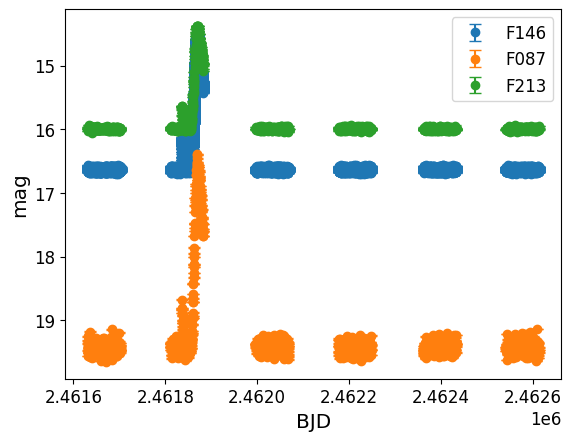

  0%|          | 0/1100 [00:02<?, ?it/s]


NameError: name 'dfadfasdf' is not defined

In [21]:
for event in tqdm(cv_dn_events['name']):
    names.append(event)
    
    ### SELECT LIGHT CURVE PER EVENT
    lc_data = con.execute("""
        SELECT *
        FROM 'hf://datasets/RGES-PIT/FalsePositives/cv.parquet'
        WHERE name = ?
    """, [str(event)]).df()
    #print(lc_data)

    # get columns to match pyAethra config
    lc_data['bjd'] = lc_data['JD']
    lc_data['mag_err'] = lc_data['mag_error']

    # break out f146 filter for achromaticity test
    f146_df = lc_data.loc[lc_data['filter']=='F146']

    # plot for slides and stuff
    f087_df = lc_data.loc[lc_data['filter']=='F087']
    f213_df = lc_data.loc[lc_data['filter']=='F213']
    plt.errorbar(f146_df['bjd'], f146_df['mag'], f146_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F146')
    plt.errorbar(f087_df['bjd'], f087_df['mag'], f087_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F087')
    plt.errorbar(f213_df['bjd'], f213_df['mag'], f213_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F213')
    plt.xlabel('BJD')
    plt.ylabel('mag')
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()
    dfadfasdf

    ### EVENT DETECTION WITH PYAETHRA
    labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores = detection(lc_data, f146_df, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores)

df_cv = pd.DataFrame({'name': names, 'label': labels, 't0': t0s, 'tE': tEs, 'u0': u0s, 't0_anomaly': t0_anomalies, 'jacscanomaly_score': jacscanomaly_scores})
print(df_cv)
df_cv.to_csv(root_dir+'data/reliability_wg6_cv.csv', index=False)



In [15]:
len(u0s), len(t0_anomalies)

(1104, 1103)

In [14]:
len(names), len(labels), len(jacscanomaly_scores), len(t0s)

(0, 1104, 1103, 1104)

Great! Now let's do it for the other variability archetypes. 

fl


  0%|          | 0/1150 [00:00<?, ?it/s]

  54,036 rows, columns: ['name', 'JD', 'mag', 'mag_error', 'filter', 'bjd', 'mag_err']
label:  microlensing
t0:  11671.111372080632
u0:  1.9508735409821898
tE:  0.9835852284553916
running jacscanomaly...


  0%|          | 1/1150 [00:13<4:17:39, 13.45s/it]

does not pass score threshold of 10


  0%|          | 2/1150 [00:13<1:50:55,  5.80s/it]

  54,036 rows, columns: ['name', 'JD', 'mag', 'mag_error', 'filter', 'bjd', 'mag_err']
label:  variable star
  53,858 rows, columns: ['name', 'JD', 'mag', 'mag_error', 'filter', 'bjd', 'mag_err']
label:  microlensing
t0:  11831.070579107385
u0:  0.09052032408526249
tE:  8.50529167044075
running jacscanomaly...


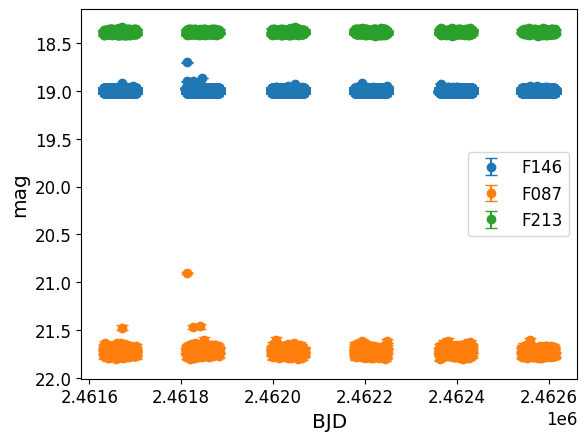

  0%|          | 2/1150 [00:30<4:53:02, 15.32s/it]


NameError: name 'dfadfasdf' is not defined

In [25]:
def detection(lc_data, f146_df):#, ss, qs, alphas, rhos):

    ### EVENT DETECTION WITH PYAETHRA
    aethra_results_df = load_and_run(lc_data, aethra_config)
    label = aethra_results_df['label'].iloc[0]
    print("label: ", label)

    ### this is logic for proceeding to next event in the loop if pyAethra fails to find a bound or free-floating planet candidate
    if (label != 'microlensing') and (label != 'ffp'):
        t0_fit = np.nan
        tE_fit = np.nan
        u0_fit = np.nan
        t0_anomaly = np.nan
        jacscanomaly_score = np.nan

    else:
        t0_fit = aethra_results_df['t0_fit'].iloc[0]
        u0_fit = aethra_results_df['u0_fit'].iloc[0]
        tE_fit = aethra_results_df['tE_fit'].iloc[0]
        print("t0: ", t0_fit)
        print("u0: ", u0_fit)
        print("tE: ", tE_fit)

        ### ANOMALY DETECTION WITH JACSCANOMALY
        time = np.array(f146_df["bjd"])
        mag = np.array(f146_df["mag"])
        magerr = np.array(f146_df["mag_err"])

        criteria = CandidateCriteria(
            min_dchi2=20.0, 
            min_n_eff=2.0,
            #min_n_contrib=2,
            #max_peak_frac=0.8,
        )
        jacscanomaly_config = FinderConfig(
            fitter_kind="pspl",
            candidate_criteria=criteria, # candidate_criteria=CandidateCriteria(min_n_eff=2.0)
            gap=150.0 # default is 50. gap between seasons is ~half a year, hence 150
        )
        finder = Finder(jacscanomaly_config)

        # initial guess is from aethra
        p0 = np.array([t0_fit, tE_fit, u0_fit]) 

        # actually run the anomaly finder. Make sure you're distinguishing between magnitude and flux. Beginner tier uses mag; experienced+ tiers use flux.
        print("running jacscanomaly...")
        anomaly_result = finder.run(time, mag, magerr, p0, data_kind="mag")
        #anomaly_result.print_summary()
        anomaly_result_summary = anomaly_result.summary_table()
        #print(anomaly_result_summary)

        # grab relevant variables
        t0_fit_best = anomaly_result_summary['best_t0'].values[0]
        #print("t0_fit_best: ", t0_fit_best)

        jacscanomaly_score = anomaly_result_summary['best_score'].values[0]
        #print("jacscanomaly_score score: ", jacscanomaly_score)

        # this is where I skip to the next event, if jacscanomaly finds nothing
        if jacscanomaly_score < 10:
            print("does not pass score threshold of 10")
            t0_anomaly = np.nan
        else:
            t0_anomaly = anomaly_result_summary['best_t0'].values[0]

    return label, t0_fit, tE_fit, u0_fit, t0_anomaly, jacscanomaly_score

def get_events(archetype):
    """
    Input:
    - archetype: variability light curve type (str)
    Output: 
    - events: list of event names
    """
    
    events = con.execute(f"""
    SELECT DISTINCT name
    FROM 'hf://datasets/RGES-PIT/FalsePositives/{archetype}.parquet'
""").df()

    return events

def get_time_series(event, archetype):
    """
    Input:
    - event: event id (int)
    - archetype: variability light curve type (str)
    Output:
    - lc_data: DataFrame of event data
    """

    lc_data = con.execute(f"""
        SELECT *
        FROM 'hf://datasets/RGES-PIT/FalsePositives/{archetype}.parquet'
        WHERE name = ?
    """, [str(event)]).df()

    # get columns to match pyAethra config
    lc_data['bjd'] = lc_data['JD']
    lc_data['mag_err'] = lc_data['mag_error']

    # break out f146 filter for achromaticity test
    f146_df = lc_data.loc[lc_data['filter']=='F146']

    return lc_data, f146_df

archetypes = ['cep','dsct','cv','ecl','ell','fl','hb','lpv','rrlyr','t2cep'] # from file.parquet names in huggingface
archetypes = archetypes[1:] # since we already ran cep's
archetypes = ['rrlyr','t2cep'] # from file.parquet names in huggingface
archetypes = ['fl','cv'] # the two biggest offenders when visualizing bad ones

for archetype in archetypes:
    print(archetype)
    events = get_events(archetype)
    #events = events[:20]

    names = []
    labels = []
    t0s = []
    tEs = []
    u0s = []
    t0_anomalies = []
    jacscanomaly_scores = []
    for event in tqdm(events['name']):
        lc_data, f146_df = get_time_series(event, archetype)
        label, t0_fit, tE_fit, u0_fit, t0_anomaly, jacscanomaly_score = detection(lc_data, f146_df)

        if jacscanomaly_score>10:
            # plot for slides and stuff
            f087_df = lc_data.loc[lc_data['filter']=='F087']
            f213_df = lc_data.loc[lc_data['filter']=='F213']
            plt.errorbar(f146_df['bjd'], f146_df['mag'], f146_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F146')
            plt.errorbar(f087_df['bjd'], f087_df['mag'], f087_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F087')
            plt.errorbar(f213_df['bjd'], f213_df['mag'], f213_df['mag_err'], linestyle='none', marker='o', capsize=4, label='F213')
            plt.xlabel('BJD')
            plt.ylabel('mag')
            plt.gca().invert_yaxis()
            plt.legend()
            plt.show()
            dfadfasdf
    
        names.append(event)
        labels.append(label)
        t0s.append(t0_fit)
        u0s.append(u0_fit)
        tEs.append(tE_fit)
        t0_anomalies.append(t0_anomaly)
        jacscanomaly_scores.append(jacscanomaly_score)

    df_archetype = pd.DataFrame({'name': names, 'label': labels, 't0': t0s, 'tE': tEs, 'u0': u0s, 't0_anomaly': t0_anomalies, 'jacscanomaly_score': jacscanomaly_scores})
    print(df_archetype)
    df_archetype.to_csv(root_dir+f'data/reliability_wg6_{archetype}.csv', index=False)



In [ ]:
fl_events = con.execute("""
    SELECT DISTINCT name
    FROM 'hf://datasets/RGES-PIT/FalsePositives/fl.parquet'
""").df()
print(fl_events)

for event in tqdm(fl_events['name']):
    ### SELECT LIGHT CURVE PER EVENT
    lc_data = con.execute("""
        SELECT *
        FROM 'hf://datasets/RGES-PIT/FalsePositives/fl.parquet'
        WHERE name = ?
    """, [str(event)]).df()
    #print(lc_data)

    # get columns to match pyAethra config
    lc_data['bjd'] = lc_data['JD']
    lc_data['mag_err'] = lc_data['mag_error']

    # break out f146 filter for achromaticity test
    f146_df = lc_data.loc[lc_data['filter']=='F146']

    ### EVENT DETECTION WITH PYAETHRA
    labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores = detection(lc_data, f146_df, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores)

df_fl = pd.DataFrame({'name': names, 'label': labels, 't0': t0s, 'tE': tEs, 'u0': u0s, 't0_anomaly': t0_anomalies, 'jacscanomaly_score': jacscanomaly_scores})
print(df_fl)
df_cv.to_csv(root_dir+'data/reliability_wg6_fl.csv', index=False)




In [21]:
meta_df = con.execute("""
    SELECT name, filename, vartype
    FROM 'hf://datasets/RGES-PIT/FalsePositives/meta.parquet' WHERE vartype=='cv_dn' LIMIT 10
""").df()
print(meta_df)

                      name                                           filename  \
0  OGLE-BLG-DN-0001_ind0_3  /Users/chrislam/Desktop/microlensing/data/fals...   
1  OGLE-BLG-DN-0001_ind1_4  /Users/chrislam/Desktop/microlensing/data/fals...   
2  OGLE-BLG-DN-0001_ind2_1  /Users/chrislam/Desktop/microlensing/data/fals...   
3  OGLE-BLG-DN-0001_ind3_1  /Users/chrislam/Desktop/microlensing/data/fals...   
4  OGLE-BLG-DN-0001_ind4_2  /Users/chrislam/Desktop/microlensing/data/fals...   
5  OGLE-BLG-DN-0001_ind5_2  /Users/chrislam/Desktop/microlensing/data/fals...   
6  OGLE-BLG-DN-0001_ind6_1  /Users/chrislam/Desktop/microlensing/data/fals...   
7  OGLE-BLG-DN-0001_ind7_3  /Users/chrislam/Desktop/microlensing/data/fals...   
8  OGLE-BLG-DN-0001_ind8_3  /Users/chrislam/Desktop/microlensing/data/fals...   
9  OGLE-BLG-DN-0001_ind9_1  /Users/chrislam/Desktop/microlensing/data/fals...   

  vartype  
0   cv_dn  
1   cv_dn  
2   cv_dn  
3   cv_dn  
4   cv_dn  
5   cv_dn  
6   cv_dn  
7   cv_dn  


In [ ]:
# create global table columns
names = []
labels = []
t0s = []
tEs = []
u0s = []
t0_anomalies = []
jacscanomaly_scores = []
ss = []
qs = []
alphas = []
rhos = []

for i in tqdm(range(len(cv_files))):
    fits_image_filename = cv_files[i] 
    try:
        lc_data, names, f146_df = process_event(cv_path, fits_image_filename, names)
    except Exception as e:
        print(f"Error processing {fits_image_filename}: {e}")
        labels.append(np.nan)
        t0s.append(np.nan)
        tEs.append(np.nan)
        u0s.append(np.nan)
        t0_anomalies.append(np.nan)
        jacscanomaly_scores.append(np.nan)
        continue

    labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores = detection(lc_data, f146_df, labels, t0s, tEs, u0s, t0_anomalies, jacscanomaly_scores)

    """
    # visualize
    if labels[i] == 'microlensing' or labels[i] == 'ffp':
        f146_df['bjd-2450000'] = f146_df['bjd'] - 2450000
        plt.errorbar(f146_df['bjd-2450000'], f146_df.mag, yerr=f146_df.mag_err, fmt='o', markersize=2, alpha=0.5)
        plt.xlabel('BJD-2450000')
        plt.ylabel('F146 mag')
        plt.gca().invert_yaxis()
        plt.vlines(t0s[i], min(f146_df.mag), max(f146_df.mag), color='r', linestyle='--', label='t0', zorder=100)
        plt.title(f"{names[i]}")# | label: {labels[i]} | t0 anomaly: {t0_anomalies[i]} | jacscanomaly score: {jacscanomaly_scores[i]}")
        plt.legend()
        plt.tight_layout()
        plt.show()

        f146_df_zoom = f146_df.loc[f146_df['bjd-2450000'].between(t0s[i]-5*tEs[i], t0s[i]+5*tEs[i])]
        plt.errorbar(f146_df_zoom['bjd-2450000'], f146_df_zoom.mag, yerr=f146_df_zoom.mag_err, fmt='o', markersize=2, alpha=0.5)
        plt.xlabel('BJD-2450000')
        plt.ylabel('F146 mag')
        plt.gca().invert_yaxis()
        plt.vlines(t0s[i], min(f146_df_zoom.mag), max(f146_df_zoom.mag), color='r', linestyle='--', label='t0', zorder=100)
        plt.title(f"{names[i]}, zoomed in")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        continue
    """

df_cv = pd.DataFrame({'name': names, 'label': labels, 't0': t0s, 'tE': tEs, 'u0': u0s, 't0_anomaly': t0_anomalies, 'jacscanomaly_score': jacscanomaly_scores})
print(df_cv)
df_cv.to_csv(root_dir+'data/reliability_wg6_cv.csv', index=False)
